# Highway Networks — Depth Experiments

**Notebook:** `04_depth_experiments.ipynb`  
**Research question:** As the number of internal layers increases, do Highway CNNs remain easier to optimize than ordinary CNNs?

This extends our four-layer CIFAR-10 comparison. **It is a small-scale depth study, not an exact replication of the original paper.** We will train both model families **from scratch** using the same 45k/5k training/validation split and compare training loss, validation accuracy, and parameter counts. The test set will not be used for model selection.

## 1. Hypothesis and experimental design

A convolutional Highway Layer computes:

$$
\boxed{y = H(x)\odot T(x) + x\odot(1-T(x))}
$$

where $H(x)$ is a convolution followed by ReLU, $T(x)$ is a sigmoid convolutional transform gate, and $\odot$ means element-wise multiplication. When $T(x)\approx 0$, then $y\approx x$, so information has a more direct path through the layer.

A Standard CNN block computes:

$$
\boxed{y=\operatorname{ReLU}(\operatorname{Conv}(x))}
$$

**Hypothesis:** At greater depths, a Highway CNN may be easier to optimize than a conventional CNN with the same number of internal blocks.

| Setting | Value |
|---|---|
| Internal block counts | 4, 10, 20 |
| Feature channels | 32 |
| Training / validation images | 45,000 / 5,000 |
| Optimizer | Adam, learning rate 0.001 |
| Batch size | 128 |
| Epochs | 10 by default (adjust for testing) |
| Random seed | 42 |

**Limitations:** Each Highway Layer has two convolutions, so parameter counts and computation differ. Our models also have no intermediate spatial downsampling. This investigates optimization of these particular models—not whether gating alone is responsible for any difference.

## 2. Imports and project setup

Run this notebook from the project `notebooks/` directory (or the project root). Reuse the `src/highway.py` and `src/model.py` files from our training notebook.

In [2]:
import sys
from pathlib import Path
import random
import time

import numpy as np
import torch
import torch.nn as nn
import torchvision
from torchvision import transforms
from torch.utils.data import DataLoader, Subset
import matplotlib.pyplot as plt

working_dir = Path.cwd().resolve()
PROJECT_ROOT = working_dir if (working_dir / "src").is_dir() else working_dir.parent
if not (PROJECT_ROOT / "src" / "model.py").is_file():
    raise FileNotFoundError("Cannot find src/model.py. Start Jupyter from notebooks/ or the project root.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.model import HighwayCNN, StandardCNN

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Project root:", PROJECT_ROOT)
print("Device:", device)

Project root: C:\Users\rbern\Desktop\DL\highway-networks
Device: cuda


## 3. CIFAR-10 training and validation data

We reproduce the **same split rule as Section 6** of `03_cifar10_training.ipynb`: `torch.randperm(50000, generator=torch.Generator().manual_seed(42))`; the first 5,000 indices are validation, and the remainder are training.

- Training images: random crop, horizontal flip, normalization.
- Validation images: normalization only.
- **No test-set evaluation** during this experiment.

In [3]:
CIFAR10_MEAN = (0.4914, 0.4822, 0.4465)
CIFAR10_STD = (0.2470, 0.2435, 0.2616)
BATCH_SIZE = 128

train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(CIFAR10_MEAN, CIFAR10_STD),
])
val_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(CIFAR10_MEAN, CIFAR10_STD),
])

full_train = torchvision.datasets.CIFAR10(
    root=str(PROJECT_ROOT / "data"), train=True, download=True,
    transform=train_transform,
)
full_val = torchvision.datasets.CIFAR10(
    root=str(PROJECT_ROOT / "data"), train=True, download=False,
    transform=val_transform,
)

split_generator = torch.Generator().manual_seed(SEED)
indices = torch.randperm(len(full_train), generator=split_generator).tolist()
val_indices = indices[:5000]
train_indices = indices[5000:]
assert set(val_indices).isdisjoint(train_indices)

train_subset = Subset(full_train, train_indices)
val_subset = Subset(full_val, val_indices)

val_loader = DataLoader(
    val_subset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0,
    pin_memory=(device.type == "cuda"),
)

def make_train_loader(seed=SEED):
    # Reinitialize the shuffling generator for each fresh model run.
    return DataLoader(
        train_subset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0,
        pin_memory=(device.type == "cuda"),
        generator=torch.Generator().manual_seed(seed),
    )

print("Train:", len(train_subset), "Validation:", len(val_subset))
print("Training batches:", len(make_train_loader()))
print("Validation batches:", len(val_loader))

Train: 45000 Validation: 5000
Training batches: 352
Validation batches: 40


## 4. Initialize and verify models at increasing depths

We interpret **depth** as the number of *internal blocks* (`num_highway_layers` / `num_layers`), not the total number of PyTorch modules or convolutions. We create **fresh models** for every run.

First run a smoke test on random data to confirm that each network outputs 10 logits and supports backpropagation.

In [4]:
DEPTHS = [4, 10, 20]
CHANNELS = 32
GATE_BIAS = -2.0
EPOCHS = 10  # For a quick pipeline check, set to 1 first; reset to 10 for your final experiment.
LR = 0.001


def build_model(kind, depth):
    if kind == "highway":
        return HighwayCNN(
            num_classes=10, channels=CHANNELS,
            num_highway_layers=depth, gate_bias=GATE_BIAS,
        )
    if kind == "standard":
        return StandardCNN(num_classes=10, channels=CHANNELS, num_layers=depth)
    raise ValueError(f"Unknown model kind: {kind}")


def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

for depth in DEPTHS:
    for kind in ("standard", "highway"):
        torch.manual_seed(SEED)
        net = build_model(kind, depth).to(device)
        x = torch.randn(2, 3, 32, 32, device=device)
        logits = net(x)
        loss = nn.CrossEntropyLoss()(logits, torch.tensor([0, 1], device=device))
        loss.backward()
        assert logits.shape == (2, 10)
        assert torch.isfinite(logits).all()
        assert all(p.grad is not None for p in net.parameters() if p.requires_grad)
        print(f"{kind:8s} | {depth:2d} blocks | {count_parameters(net):>8,d} parameters | PASS")
        del net, x, logits, loss

standard |  4 blocks |   38,218 parameters | PASS
highway  |  4 blocks |   75,210 parameters | PASS
standard | 10 blocks |   93,706 parameters | PASS
highway  | 10 blocks |  186,186 parameters | PASS
standard | 20 blocks |  186,186 parameters | PASS
highway  | 20 blocks |  371,146 parameters | PASS


## 5. Training and evaluation functions

For every epoch we record the **sample-weighted average cross-entropy** and accuracy. Validation uses `model.eval()` and does not update weights. We also measure wall-clock training time.

**Practical note:** Six training runs at 10 epochs each may take a while, especially at 20 blocks. Start by verifying the notebook with `EPOCHS=1` if you want a fast smoke test; change it back to 10 and rerun with fresh models for your real experiment.

In [5]:
def train_one_epoch(net, loader, criterion, optimizer):
    net.train()
    loss_sum = 0.0
    correct = 0
    total = 0
    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        logits = net(images)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()
        batch_n = labels.size(0)
        loss_sum += loss.item() * batch_n
        correct += (logits.argmax(1) == labels).sum().item()
        total += batch_n
    return loss_sum / total, 100 * correct / total


@torch.no_grad()
def evaluate(net, loader, criterion):
    net.eval()
    loss_sum = 0.0
    correct = 0
    total = 0
    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        logits = net(images)
        loss = criterion(logits, labels)
        batch_n = labels.size(0)
        loss_sum += loss.item() * batch_n
        correct += (logits.argmax(1) == labels).sum().item()
        total += batch_n
    return loss_sum / total, 100 * correct / total

## 6. Run the depth comparison

This trains **six fresh models**: Standard and Highway, each at 4, 10, and 20 internal blocks. The training loop stores histories and saves checkpoints in `checkpoints/depth_experiments/`. No test images are used.

If you run the cell again, it will **retrain** all six networks and overwrite their checkpoints.

In [6]:
checkpoint_dir = PROJECT_ROOT / "checkpoints" / "depth_experiments"
checkpoint_dir.mkdir(parents=True, exist_ok=True)

results = {}
criterion = nn.CrossEntropyLoss()

for depth in DEPTHS:
    for kind in ("standard", "highway"):
        # Fresh initialization; resetting helps make runs reproducible.
        torch.manual_seed(SEED)
        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(SEED)
        net = build_model(kind, depth).to(device)
        optimizer = torch.optim.Adam(net.parameters(), lr=LR)
        loader = make_train_loader(seed=SEED)
        history = {"train_loss": [], "train_accuracy": [],
                   "val_loss": [], "val_accuracy": []}
        started = time.perf_counter()
        print(f"\nTraining {kind} CNN — {depth} internal blocks")
        for epoch in range(1, EPOCHS + 1):
            train_loss, train_acc = train_one_epoch(net, loader, criterion, optimizer)
            val_loss, val_acc = evaluate(net, val_loader, criterion)
            history["train_loss"].append(train_loss)
            history["train_accuracy"].append(train_acc)
            history["val_loss"].append(val_loss)
            history["val_accuracy"].append(val_acc)
            print(f"  Epoch {epoch:02d}/{EPOCHS} | train loss {train_loss:.4f} "
                  f"| train acc {train_acc:.2f}% | val loss {val_loss:.4f} "
                  f"| val acc {val_acc:.2f}%")

        elapsed = time.perf_counter() - started
        results[(kind, depth)] = {
            "history": history,
            "parameters": count_parameters(net),
            "seconds": elapsed,
        }
        torch.save({
            "model_state_dict": net.state_dict(), "kind": kind,
            "depth": depth, "channels": CHANNELS, "gate_bias": GATE_BIAS,
            "epochs": EPOCHS, "seed": SEED, "history": history,
            "validation_accuracy": history["val_accuracy"][-1],
        }, checkpoint_dir / f"{kind}_{depth}blocks.pth")
        print(f"  Completed in {elapsed / 60:.1f} minutes; checkpoint saved.")
        del net, optimizer, loader

print("\nFinished all depth experiments!")


Training standard CNN — 4 internal blocks
  Epoch 01/10 | train loss 2.0301 | train acc 21.75% | val loss 1.8269 | val acc 29.92%
  Epoch 02/10 | train loss 1.7736 | train acc 31.39% | val loss 1.7194 | val acc 33.82%
  Epoch 03/10 | train loss 1.6759 | train acc 36.08% | val loss 1.6834 | val acc 36.78%
  Epoch 04/10 | train loss 1.5821 | train acc 40.47% | val loss 1.6598 | val acc 37.88%
  Epoch 05/10 | train loss 1.4972 | train acc 44.70% | val loss 1.4520 | val acc 46.84%
  Epoch 06/10 | train loss 1.4253 | train acc 47.97% | val loss 1.4757 | val acc 46.26%
  Epoch 07/10 | train loss 1.3579 | train acc 50.56% | val loss 1.3694 | val acc 51.52%
  Epoch 08/10 | train loss 1.3083 | train acc 52.56% | val loss 1.2838 | val acc 54.92%
  Epoch 09/10 | train loss 1.2815 | train acc 53.89% | val loss 1.2852 | val acc 53.62%
  Epoch 10/10 | train loss 1.2402 | train acc 55.31% | val loss 1.2442 | val acc 56.68%
  Completed in 4.3 minutes; checkpoint saved.

Training highway CNN — 4 inter

## 7. Visualize learning across depths

A strong sign of optimization difficulty would be **persistently high training loss** at greater depth. Validation accuracy alone cannot identify an optimization problem because generalization and model capacity also matter.

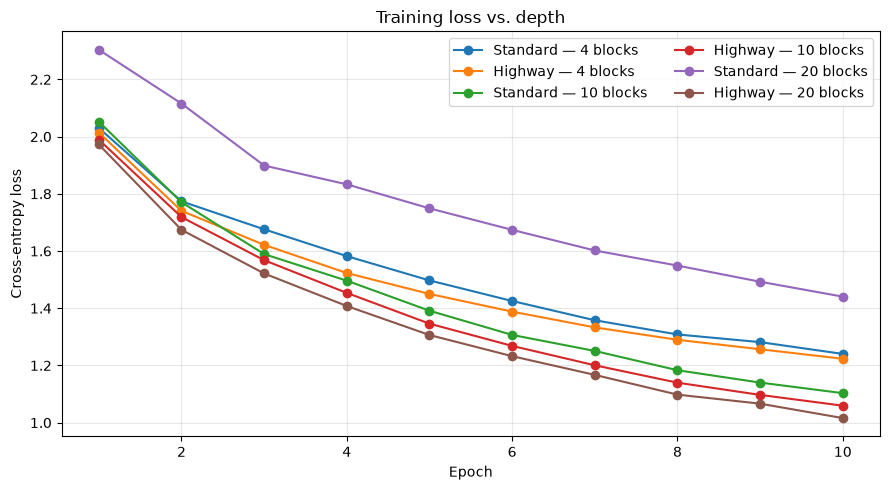

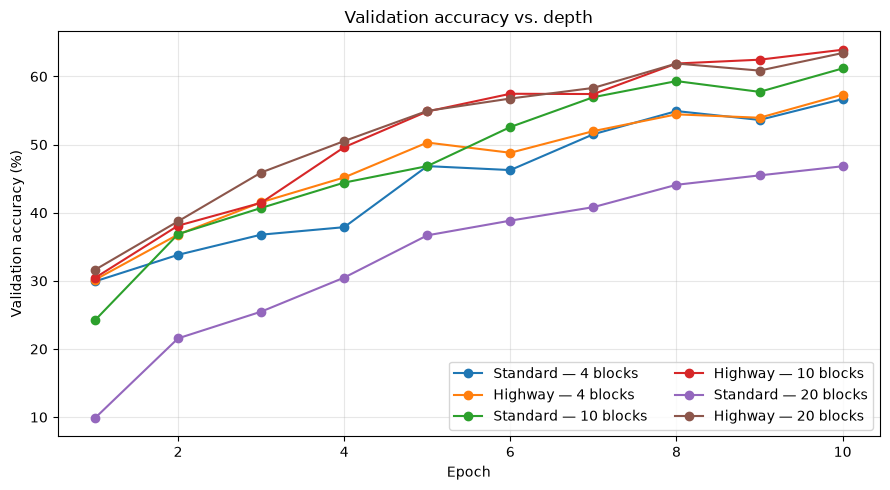

In [7]:
# One separate chart per metric, with all model-depth runs on it.
for metric, ylabel, title in [
    ("train_loss", "Cross-entropy loss", "Training loss vs. depth"),
    ("val_accuracy", "Validation accuracy (%)", "Validation accuracy vs. depth"),
]:
    plt.figure(figsize=(9, 5))
    for depth in DEPTHS:
        for kind in ("standard", "highway"):
            h = results[(kind, depth)]["history"]
            plt.plot(range(1, len(h[metric]) + 1), h[metric], marker="o",
                     label=f"{kind.title()} — {depth} blocks")
    plt.xlabel("Epoch")
    plt.ylabel(ylabel)
    plt.title(title)
    plt.grid(alpha=0.3)
    plt.legend(ncol=2)
    plt.tight_layout()
    plt.show()

## 8. Final result summary

This table is generated without pandas. Compare final **training loss** first to assess optimization, then validation accuracy and parameter counts.

In [8]:
header = f"{'Model':<10} {'Blocks':>6} {'Params':>9} {'Train loss':>11} {'Val loss':>10} {'Val acc':>10} {'Time (min)':>11}"
print(header)
print("-" * len(header))
for depth in DEPTHS:
    for kind in ("standard", "highway"):
        result = results[(kind, depth)]
        h = result["history"]
        print(f"{kind.title():<10} {depth:>6} {result['parameters']:>9,d} "
              f"{h['train_loss'][-1]:>11.4f} {h['val_loss'][-1]:>10.4f} "
              f"{h['val_accuracy'][-1]:>9.2f}% {result['seconds']/60:>11.1f}")

Model      Blocks    Params  Train loss   Val loss    Val acc  Time (min)
-------------------------------------------------------------------------
Standard        4    38,218      1.2402     1.2442     56.68%         4.3
Highway         4    75,210      1.2232     1.2227     57.34%         6.5
Standard       10    93,706      1.1031     1.0826     61.18%         6.2
Highway        10   186,186      1.0593     1.0349     63.92%         9.2
Standard       20   186,186      1.4405     1.4310     46.82%         8.3
Highway        20   371,146      1.0160     1.0560     63.44%        14.7



## 8. Results and Conclusions

### 8.1 Experimental Results

We compared Standard CNNs and Highway CNNs with 4, 10, and 20 internal blocks on CIFAR-10.

All models were trained from scratch using the same training and validation split, optimizer, learning rate, and training duration.

| Model | Blocks | Parameters | Train Loss | Val Loss | Val Accuracy | Time (min) |
|---|---:|---:|---:|---:|---:|---:|
| Standard CNN | 4 | 38,218 | 1.2402 | 1.2442 | 56.68% | 4.3 |
| Highway CNN | 4 | 75,210 | 1.2232 | 1.2227 | 57.34% | 6.5 |
| Standard CNN | 10 | 93,706 | 1.1031 | 1.0826 | 61.18% | 6.2 |
| Highway CNN | 10 | 186,186 | 1.0593 | 1.0349 | **63.92%** | 9.2 |
| Standard CNN | 20 | 186,186 | 1.4405 | 1.4310 | 46.82% | 8.3 |
| Highway CNN | 20 | 371,146 | 1.0160 | 1.0560 | 63.44% | 14.7 |

### 8.2 Accuracy Comparison

| Depth | Standard CNN | Highway CNN | Difference |
|---|---:|---:|---:|
| 4 | 56.68% | 57.34% | +0.66 pp |
| 10 | 61.18% | 63.92% | +2.74 pp |
| 20 | 46.82% | 63.44% | **+16.62 pp** |

The largest performance difference occurred at 20 layers.

### 8.3 Observations

**1. Shallow networks performed similarly.**

At 4 layers, the Highway CNN achieved 57.34% validation accuracy compared with 56.68% for the Standard CNN.

The difference was only 0.66 percentage points.

**2. Both architectures benefited from moderate depth.**

At 10 layers, both models achieved higher validation accuracy than their 4-layer counterparts.

The Highway CNN achieved the highest validation accuracy of the experiment: **63.92%**.

**3. The Standard CNN struggled at greater depth.**

Increasing depth from 10 to 20 layers reduced its validation accuracy:

$$
61.18\%-46.82\%=14.36\text{ percentage points}
$$

Its training loss also increased from 1.1031 to 1.4405.

This suggests that the deeper Standard CNN was harder to optimize under the tested training conditions.

**4. The Highway CNN maintained performance at 20 layers.**

The Highway CNN achieved 63.44% validation accuracy at 20 layers, compared with 63.92% at 10 layers.

Its training loss continued to decrease as depth increased:

$$
1.2232\rightarrow1.0593\rightarrow1.0160
$$

This is consistent with Highway Layers helping preserve information flow in deeper architectures.

**5. Highway Networks required more computation.**

At 20 layers:

- Standard CNN: 8.3 minutes
- Highway CNN: 14.7 minutes

The Highway architecture used more parameters and required more training time.

### 8.4 Connection to the Original Paper

The original *Highway Networks* paper argues that learned gating mechanisms help very deep neural networks train successfully.

The Highway Layer computes:

$$
y=H(x)T(x)+x(1-T(x))
$$

When the transform gate is small:

$$
T(x)\approx0 \implies y\approx x
$$

The carry path allows information to pass through the network with less modification.

Our results are consistent with this motivation:

- At shallow depths, both architectures performed similarly.
- At greater depth, the Standard CNN showed substantially worse optimization and validation performance.
- The Highway CNN maintained comparable performance as its depth increased from 10 to 20 layers.

### 8.5 Experimental Limitations

- Each configuration was trained only once.
- The architectures had different parameter counts at the same depth.
- All models used the same fixed training budget.
- We did not directly measure gradient norms.
- The results are based on our simplified CNN architectures, not an exact reproduction of the original paper.

Therefore, the results support the hypothesis that Highway Layers improve optimization at greater depths, but more controlled experiments are required to establish the cause.

### 8.6 Final Conclusion

Our depth experiment provides evidence that Highway Networks can be easier to optimize than conventional CNNs as depth increases.

The strongest evidence appeared at 20 layers:

$$
\boxed{
\text{Highway CNN: }63.44\%
}
$$

$$
\boxed{
\text{Standard CNN: }46.82\%
}
$$

The Highway CNN outperformed the Standard CNN by **16.62 percentage points** in validation accuracy.

The Standard CNN's training loss increased substantially at 20 layers, while the Highway CNN maintained a low training loss.

**Final takeaway:** Our experiment reproduces the qualitative behavior motivating the original Highway Networks paper: learned carry gates can help maintain trainability as neural networks become deeper.



## 9. Very Deep Networks — 50 and 100 Layers

### 9.1 Research Question

Our previous experiment compared Standard CNNs and Highway CNNs with 4, 10, and 20 internal blocks.

At 20 blocks, we observed:

| Model | Validation Accuracy | Training Loss |
|---|---:|---:|
| Standard CNN | 46.82% | 1.4405 |
| Highway CNN | 63.44% | 1.0160 |

The Standard CNN became harder to optimize as depth increased, while the Highway CNN maintained similar performance.

We now investigate whether this difference becomes more pronounced at 50 and 100 blocks.

### 9.2 Hypothesis

Highway Networks may train more effectively at greater depths because their learned carry gates allow information to bypass transformations.

The Highway equation is:

$$
y = H(x)T(x) + x(1-T(x))
$$

When the transform gate is small:

$$
T(x)\approx0
$$

Then:

$$
y\approx x
$$

This creates an approximately identity-preserving information path.

### 9.3 Experimental Configuration

We will train:

- Standard CNN with 50 blocks.
- Highway CNN with 50 blocks.
- Standard CNN with 100 blocks.
- Highway CNN with 100 blocks.

We will use the existing:

- CIFAR-10 training/validation split.
- 32 feature channels.
- Adam optimizer.
- Learning rate of 0.001.
- Batch size of 128.
- Cross-entropy loss.
- Negative transform gate bias initialization of -2.

### 9.4 Metrics

We will record:

1. Training loss and accuracy.
2. Validation loss and accuracy.
3. Training duration.
4. Trainable parameter counts.
5. Gradient behavior where useful.

### 9.5 Limitations

- The Highway CNN has more parameters than the Standard CNN at the same depth.
- Very deep networks may require different learning rates or initialization strategies.
- A single training run is insufficient to establish statistical significance.
- Our models are simplified CNNs rather than exact reproductions of the original paper.

**Objective:** Determine whether increasing network depth causes greater optimization difficulties for conventional CNNs than for Highway CNNs.


In [9]:
DEEP_DEPTHS = [50, 100]

# Start with a short verification run.
DEEP_EPOCHS = 1

for depth in DEEP_DEPTHS:
    for kind in ("standard", "highway"):
        net = build_model(kind, depth)

        print(
            f"{kind:8s} | "
            f"Depth: {depth:3d} | "
            f"Parameters: {count_parameters(net):,}"
        )

        del net

standard | Depth:  50 | Parameters: 463,626
highway  | Depth:  50 | Parameters: 926,026
standard | Depth: 100 | Parameters: 926,026
highway  | Depth: 100 | Parameters: 1,850,826


In [10]:
torch.manual_seed(SEED)

for depth in DEEP_DEPTHS:
    for kind in ("standard", "highway"):
        print(f"\nTesting {kind} CNN with {depth} blocks")

        net = build_model(kind, depth).to(device)
        net.train()

        # Small batch for verification
        x = torch.randn(
            4, 3, 32, 32,
            device=device
        )

        labels = torch.randint(
            0, 10, (4,),
            device=device
        )

        net.zero_grad(set_to_none=True)

        logits = net(x)
        loss = nn.CrossEntropyLoss()(logits, labels)

        loss.backward()

        assert logits.shape == (4, 10)
        assert torch.isfinite(loss).item()

        print("Output shape:", logits.shape)
        print("Loss:", loss.item())
        print("Backward pass successful!")

        del net, x, labels, logits, loss

        if device.type == "cuda":
            torch.cuda.empty_cache()


Testing standard CNN with 50 blocks
Output shape: torch.Size([4, 10])
Loss: 2.3589000701904297
Backward pass successful!

Testing highway CNN with 50 blocks
Output shape: torch.Size([4, 10])
Loss: 2.2158448696136475
Backward pass successful!

Testing standard CNN with 100 blocks
Output shape: torch.Size([4, 10])
Loss: 2.3638243675231934
Backward pass successful!

Testing highway CNN with 100 blocks
Output shape: torch.Size([4, 10])
Loss: 2.3040947914123535
Backward pass successful!


In [11]:
DEEP_EPOCHS = 10

deep_results = {}

for kind in ("standard", "highway"):
    depth = 50

    torch.manual_seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)

    net = build_model(kind, depth).to(device)

    optimizer = torch.optim.Adam(
        net.parameters(),
        lr=LR
    )

    loader = make_train_loader(seed=SEED)

    history = {
        "train_loss": [],
        "train_accuracy": [],
        "val_loss": [],
        "val_accuracy": [],
    }

    started = time.perf_counter()

    print(f"\nTraining {kind} CNN — {depth} blocks")

    for epoch in range(1, DEEP_EPOCHS + 1):
        train_loss, train_acc = train_one_epoch(
            net, loader, criterion, optimizer
        )

        val_loss, val_acc = evaluate(
            net, val_loader, criterion
        )

        history["train_loss"].append(train_loss)
        history["train_accuracy"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_accuracy"].append(val_acc)

        print(
            f"Epoch {epoch:02d}/{DEEP_EPOCHS} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Train Acc: {train_acc:.2f}% | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Acc: {val_acc:.2f}%"
        )

    elapsed = time.perf_counter() - started

    deep_results[(kind, depth)] = {
        "history": history,
        "parameters": count_parameters(net),
        "seconds": elapsed,
    }

    torch.save(
        {
            "model_state_dict": net.state_dict(),
            "kind": kind,
            "depth": depth,
            "channels": CHANNELS,
            "gate_bias": GATE_BIAS,
            "history": history,
            "epochs": DEEP_EPOCHS,
            "seed": SEED,
        },
        checkpoint_dir / f"{kind}_{depth}blocks.pth",
    )

    print(f"Completed in {elapsed / 60:.1f} minutes")

    del net, optimizer, loader

    if device.type == "cuda":
        torch.cuda.empty_cache()


Training standard CNN — 50 blocks
Epoch 01/10 | Train Loss: 2.3034 | Train Acc: 9.93% | Val Loss: 2.3028 | Val Acc: 9.86%
Epoch 02/10 | Train Loss: 2.3029 | Train Acc: 9.90% | Val Loss: 2.3030 | Val Acc: 9.86%
Epoch 03/10 | Train Loss: 2.3029 | Train Acc: 9.74% | Val Loss: 2.3028 | Val Acc: 10.22%
Epoch 04/10 | Train Loss: 2.3029 | Train Acc: 9.75% | Val Loss: 2.3026 | Val Acc: 9.66%
Epoch 05/10 | Train Loss: 2.3029 | Train Acc: 9.82% | Val Loss: 2.3027 | Val Acc: 9.86%
Epoch 06/10 | Train Loss: 2.3028 | Train Acc: 9.88% | Val Loss: 2.3029 | Val Acc: 9.90%
Epoch 07/10 | Train Loss: 2.3028 | Train Acc: 9.80% | Val Loss: 2.3030 | Val Acc: 9.86%
Epoch 08/10 | Train Loss: 2.3027 | Train Acc: 9.69% | Val Loss: 2.3027 | Val Acc: 9.90%
Epoch 09/10 | Train Loss: 2.3028 | Train Acc: 9.91% | Val Loss: 2.3030 | Val Acc: 9.56%
Epoch 10/10 | Train Loss: 2.3028 | Train Acc: 9.86% | Val Loss: 2.3028 | Val Acc: 10.34%
Completed in 13.0 minutes

Training highway CNN — 50 blocks
Epoch 01/10 | Train Los

In [12]:
for kind in ("standard", "highway"):
    result = deep_results[(kind, 50)]
    history = result["history"]

    print(f"\n{kind.title()} CNN — 50 blocks")
    print(f"Parameters: {result['parameters']:,}")
    print(f"Train loss: {history['train_loss'][-1]:.4f}")
    print(f"Val loss: {history['val_loss'][-1]:.4f}")
    print(f"Val accuracy: {history['val_accuracy'][-1]:.2f}%")
    print(f"Time: {result['seconds']/60:.1f} min")


Standard CNN — 50 blocks
Parameters: 463,626
Train loss: 2.3028
Val loss: 2.3028
Val accuracy: 10.34%
Time: 13.0 min

Highway CNN — 50 blocks
Parameters: 926,026
Train loss: 0.9840
Val loss: 1.0070
Val accuracy: 66.06%
Time: 33.6 min



### 9.7 Experiment — 100-Block Networks

#### Research Objective

Our 50-block experiment produced a substantial difference between Standard CNN and Highway CNN performance.

| Metric | Standard CNN | Highway CNN |
|---|---:|---:|
| Internal blocks | 50 | 50 |
| Trainable parameters | 463,626 | 926,026 |
| Final training loss | 2.3028 | 0.9840 |
| Final validation loss | 2.3028 | 1.0070 |
| Final validation accuracy | 10.34% | **66.06%** |
| Training time | 13.0 min | 33.6 min |

The Standard CNN remained close to random classification performance, while the Highway CNN successfully learned useful visual representations.

For 10 equally likely classes, random classification has expected accuracy of approximately:

$$
A_{\text{random}}=10\%
$$

The corresponding cross-entropy loss for uniform predictions is:

$$
\mathcal{L}_{\text{uniform}}=-\log(0.1)=\log(10)\approx2.3026
$$

#### New Hypothesis

At 100 blocks, we hypothesize that:

- The Standard CNN may continue experiencing severe optimization difficulties.
- The Highway CNN may remain trainable due to learned transform and carry gates.

The Highway equation remains:

$$
y=H(x)T(x)+x(1-T(x))
$$

#### Experimental Configuration

- Network depth: 100 internal blocks
- Feature channels: 32
- Training epochs: 10
- Optimizer: Adam
- Learning rate: 0.001
- Batch size: 128
- Training images: 45,000
- Validation images: 5,000
- Random seed: 42

All settings remain consistent with the earlier depth experiments.

**Important:** The outcomes are not guaranteed. This experiment measures whether the observed optimization differences persist at greater depth.


In [13]:
DEPTH = 100

for kind in ("standard", "highway"):
    torch.manual_seed(SEED)

    net = build_model(kind, DEPTH).to(device)

    x = torch.randn(2, 3, 32, 32, device=device)
    labels = torch.randint(0, 10, (2,), device=device)

    net.zero_grad(set_to_none=True)

    logits = net(x)
    loss = criterion(logits, labels)
    loss.backward()

    print(f"\n{kind.title()} CNN — {DEPTH} blocks")
    print("Parameters:", f"{count_parameters(net):,}")
    print("Output shape:", logits.shape)
    print("Loss:", loss.item())
    print("Finite loss:", torch.isfinite(loss).item())

    assert logits.shape == (2, 10)
    assert torch.isfinite(loss).item()

    del net, x, labels, logits, loss

    if device.type == "cuda":
        torch.cuda.empty_cache()


Standard CNN — 100 blocks
Parameters: 926,026
Output shape: torch.Size([2, 10])
Loss: 2.170292377471924
Finite loss: True

Highway CNN — 100 blocks
Parameters: 1,850,826
Output shape: torch.Size([2, 10])
Loss: 2.304065704345703
Finite loss: True


In [14]:
import time
import torch

DEPTH = 100
DEEP_EPOCHS = 10

checkpoint_dir = PROJECT_ROOT / "checkpoints" / "depth_experiments"
checkpoint_dir.mkdir(parents=True, exist_ok=True)

if "deep_results" not in globals():
    deep_results = {}

for kind in ("standard", "highway"):
    torch.manual_seed(SEED)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)

    net = build_model(kind, DEPTH).to(device)

    optimizer = torch.optim.Adam(
        net.parameters(),
        lr=LR
    )

    loader = make_train_loader(seed=SEED)

    history = {
        "train_loss": [],
        "train_accuracy": [],
        "val_loss": [],
        "val_accuracy": [],
    }

    started = time.perf_counter()

    print(f"\nTraining {kind} CNN — {DEPTH} blocks")

    for epoch in range(1, DEEP_EPOCHS + 1):
        train_loss, train_acc = train_one_epoch(
            net, loader, criterion, optimizer
        )

        val_loss, val_acc = evaluate(
            net, val_loader, criterion
        )

        if not all(
            torch.isfinite(torch.tensor(v)).item()
            for v in (train_loss, train_acc, val_loss, val_acc)
        ):
            raise RuntimeError(
                f"Non-finite metric in {kind}, epoch {epoch}"
            )

        history["train_loss"].append(train_loss)
        history["train_accuracy"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_accuracy"].append(val_acc)

        print(
            f"Epoch {epoch:02d}/{DEEP_EPOCHS} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Train Acc: {train_acc:.2f}% | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Acc: {val_acc:.2f}%"
        )

        # Save progress after each completed epoch
        torch.save(
            {
                "model_state_dict": net.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "kind": kind,
                "depth": DEPTH,
                "channels": CHANNELS,
                "gate_bias": GATE_BIAS,
                "epoch": epoch,
                "seed": SEED,
                "history": history,
            },
            checkpoint_dir / f"{kind}_{DEPTH}blocks_progress.pth",
        )

    elapsed = time.perf_counter() - started

    deep_results[(kind, DEPTH)] = {
        "history": history,
        "parameters": count_parameters(net),
        "seconds": elapsed,
    }

    torch.save(
        {
            "model_state_dict": net.state_dict(),
            "kind": kind,
            "depth": DEPTH,
            "channels": CHANNELS,
            "gate_bias": GATE_BIAS,
            "epochs": DEEP_EPOCHS,
            "seed": SEED,
            "history": history,
        },
        checkpoint_dir / f"{kind}_{DEPTH}blocks.pth",
    )

    print(f"Completed in {elapsed / 60:.1f} minutes")

    del net, optimizer, loader

    if device.type == "cuda":
        torch.cuda.empty_cache()

print("\n100-block experiments completed!")


Training standard CNN — 100 blocks
Epoch 01/10 | Train Loss: 2.3040 | Train Acc: 10.20% | Val Loss: 2.3028 | Val Acc: 9.86%
Epoch 02/10 | Train Loss: 2.3030 | Train Acc: 9.95% | Val Loss: 2.3028 | Val Acc: 9.86%
Epoch 03/10 | Train Loss: 2.3029 | Train Acc: 9.98% | Val Loss: 2.3032 | Val Acc: 10.22%
Epoch 04/10 | Train Loss: 2.3029 | Train Acc: 9.95% | Val Loss: 2.3027 | Val Acc: 9.56%
Epoch 05/10 | Train Loss: 2.3029 | Train Acc: 9.85% | Val Loss: 2.3026 | Val Acc: 10.34%
Epoch 06/10 | Train Loss: 2.3028 | Train Acc: 9.77% | Val Loss: 2.3029 | Val Acc: 9.90%
Epoch 07/10 | Train Loss: 2.3029 | Train Acc: 9.73% | Val Loss: 2.3028 | Val Acc: 9.86%
Epoch 08/10 | Train Loss: 2.3027 | Train Acc: 9.97% | Val Loss: 2.3028 | Val Acc: 9.90%
Epoch 09/10 | Train Loss: 2.3029 | Train Acc: 9.84% | Val Loss: 2.3028 | Val Acc: 9.56%
Epoch 10/10 | Train Loss: 2.3028 | Train Acc: 10.01% | Val Loss: 2.3028 | Val Acc: 9.86%
Completed in 20.7 minutes

Training highway CNN — 100 blocks
Epoch 01/10 | Train

In [15]:
combined_results = {
    **results,
    **deep_results,
}

print(
    f"{'Model':<10} {'Blocks':>6} {'Params':>10} "
    f"{'Train loss':>11} {'Val loss':>10} "
    f"{'Val acc':>10} {'Time (min)':>11}"
)
print("-" * 78)

for depth in [4, 10, 20, 50, 100]:
    for kind in ("standard", "highway"):
        result = combined_results.get((kind, depth))

        if result is None:
            continue

        h = result["history"]

        print(
            f"{kind.title():<10} "
            f"{depth:>6} "
            f"{result['parameters']:>10,} "
            f"{h['train_loss'][-1]:>11.4f} "
            f"{h['val_loss'][-1]:>10.4f} "
            f"{h['val_accuracy'][-1]:>9.2f}% "
            f"{result['seconds'] / 60:>11.1f}"
        )

Model      Blocks     Params  Train loss   Val loss    Val acc  Time (min)
------------------------------------------------------------------------------
Standard        4     38,218      1.2402     1.2442     56.68%         4.3
Highway         4     75,210      1.2232     1.2227     57.34%         6.5
Standard       10     93,706      1.1031     1.0826     61.18%         6.2
Highway        10    186,186      1.0593     1.0349     63.92%         9.2
Standard       20    186,186      1.4405     1.4310     46.82%         8.3
Highway        20    371,146      1.0160     1.0560     63.44%        14.7
Standard       50    463,626      2.3028     2.3028     10.34%        13.0
Highway        50    926,026      0.9840     1.0070     66.06%        33.6
Standard      100    926,026      2.3028     2.3028      9.86%        20.7
Highway       100  1,850,826      2.3033     2.3032      9.86%       226.0


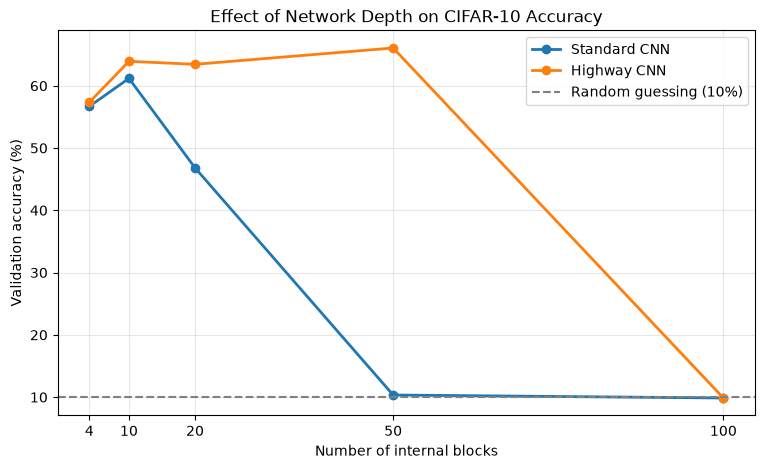

In [16]:
import matplotlib.pyplot as plt

depths = [4, 10, 20, 50, 100]

plt.figure(figsize=(9, 5))

for kind in ("standard", "highway"):
    available_depths = [
        d for d in depths
        if (kind, d) in combined_results
    ]

    accuracies = [
        combined_results[(kind, d)]["history"]["val_accuracy"][-1]
        for d in available_depths
    ]

    plt.plot(
        available_depths,
        accuracies,
        marker="o",
        linewidth=2,
        label=f"{kind.title()} CNN",
    )

plt.axhline(
    10,
    linestyle="--",
    color="gray",
    label="Random guessing (10%)",
)

plt.xlabel("Number of internal blocks")
plt.ylabel("Validation accuracy (%)")
plt.title("Effect of Network Depth on CIFAR-10 Accuracy")
plt.xticks(depths)
plt.legend()
plt.grid(alpha=0.3)
plt.show()


### 9.8 Results — 100-Block Networks

We trained Standard CNN and Highway CNN models with 100 internal blocks for 10 epochs.

| Metric | Standard CNN | Highway CNN |
|---|---:|---:|
| Internal blocks | 100 | 100 |
| Trainable parameters | 926,026 | 1,850,826 |
| Final training loss | 2.3028 | 2.3033 |
| Final validation loss | 2.3028 | 2.3032 |
| Final validation accuracy | 9.86% | 9.86% |
| Best validation accuracy | 10.34% | **36.48%** |
| Training time | 20.7 min | 226.0 min |

### Training Behavior

**Standard CNN:**

The Standard CNN remained near random classification performance throughout training.

Its loss remained approximately:

$$
\mathcal{L}\approx\log(10)\approx2.3026
$$

The model did not successfully optimize under the tested conditions.

**Highway CNN:**

The Highway CNN initially learned useful representations.

At epoch 8:

- Training accuracy: 34.06%
- Validation accuracy: 36.48%
- Training loss: 1.7722
- Validation loss: 1.7097

However, the model experienced a sharp deterioration during epoch 9.

At epoch 10:

- Training accuracy: 9.89%
- Validation accuracy: 9.86%
- Training loss: 2.3033
- Validation loss: 2.3032

The model effectively returned to random classification performance.

### Interpretation

The Highway CNN demonstrated better initial optimization than the Standard CNN at 100 blocks, but its training became unstable.

Possible explanations include:

- Learning rate being too high for the deeper architecture.
- Large gradient updates.
- Instability in the learned transformation or gate parameters.

These are hypotheses and require additional diagnostics.

### Comparison With 50 Blocks

| Depth | Standard CNN Val Accuracy | Highway CNN Val Accuracy |
|---|---:|---:|
| 50 | 10.34% | 66.06% |
| 100 | 9.86% | 9.86% |

The Highway CNN performed substantially better at 50 blocks.

At 100 blocks, it showed useful learning initially but failed to maintain performance.

### Conclusion

Our results support the observation that Highway connections can improve optimization in deeper networks.

However, they also demonstrate that Highway connections alone do not guarantee stable training at arbitrary depth.

The 100-block Highway CNN requires further optimization experiments before we can draw stronger conclusions about its performance.

**Key takeaway:** Highway Networks help information flow through deep architectures, but learning rate, initialization, and training stability remain important.



### 9.9 Improving Training Stability at 100 Blocks

#### Problem

In our previous 100-block experiment, the Highway CNN initially learned useful features but experienced a sudden performance collapse.

| Metric | Epoch 8 | Epoch 10 |
|---|---:|---:|
| Training accuracy | 34.06% | 9.89% |
| Validation accuracy | 36.48% | 9.86% |
| Training loss | 1.7722 | 2.3033 |
| Validation loss | 1.7097 | 2.3032 |

The model lost most of its classification ability during the final two epochs.

#### Hypothesis

Training instability may be related to large parameter updates or unsuitable optimizer settings.

We will investigate whether a lower learning rate and gradient clipping improve training stability.

#### Modified Configuration

| Hyperparameter | Original Experiment | Stability Experiment |
|---|---|---|
| Internal Highway blocks | 100 | 100 |
| Feature channels | 32 | 32 |
| Optimizer | Adam | Adam |
| Learning rate | 0.001 | 0.0001 |
| Gradient clipping | None | Max norm = 1.0 |
| Batch size | 128 | 128 |
| Epochs | 10 | 10 |
| Random seed | 42 | 42 |

#### Gradient Clipping

Gradient clipping limits the global norm of the gradient vector.

Let $g$ represent the collection of all parameter gradients and $c$ the maximum allowed norm.

$$
g_{\text{clipped}} =
\begin{cases}
g, & \|g\|_2 \leq c \\
\frac{c}{\|g\|_2}g, & \|g\|_2 > c
\end{cases}
$$

For this experiment:

$$
c=1.0
$$

Gradient clipping is intended to prevent excessively large gradient updates.

#### Experiment Goals

1. Check whether the 100-block Highway CNN can learn without collapsing.
2. Monitor training loss, validation accuracy, and gradient norms.
3. Save the model with the highest validation accuracy.
4. Compare the stability experiment with the original 100-block run.

**Important:** We are changing both the learning rate and gradient clipping, so this experiment tests the combined configuration rather than the effect of either change individually.


In [17]:
def train_one_epoch_stable(
    model,
    loader,
    criterion,
    optimizer,
    max_grad_norm=1.0,
):
    model.train()

    total_loss = 0.0
    correct = 0
    total = 0

    gradient_norms = []

    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        logits = model(images)
        loss = criterion(logits, labels)

        if not torch.isfinite(loss).item():
            raise RuntimeError("Non-finite training loss detected")

        loss.backward()

        # Returns the global gradient norm BEFORE clipping.
        grad_norm = torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=max_grad_norm,
            error_if_nonfinite=True,
        )

        gradient_norms.append(grad_norm.item())

        optimizer.step()

        batch_size = labels.size(0)

        total_loss += loss.item() * batch_size

        predictions = logits.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += batch_size

    return (
        total_loss / total,
        100 * correct / total,
        sum(gradient_norms) / len(gradient_norms),
        max(gradient_norms),
    )

In [18]:
import time
import torch

STABLE_DEPTH = 100
STABLE_EPOCHS = 10
STABLE_LR = 1e-4
MAX_GRAD_NORM = 1.0

checkpoint_dir = PROJECT_ROOT / "checkpoints" / "depth_experiments"
checkpoint_dir.mkdir(parents=True, exist_ok=True)

# Reproducible initialization
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

stable_model = build_model("highway", STABLE_DEPTH).to(device)

stable_optimizer = torch.optim.Adam(
    stable_model.parameters(),
    lr=STABLE_LR,
)

stable_criterion = nn.CrossEntropyLoss()
stable_loader = make_train_loader(seed=SEED)

stable_history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": [],
    "mean_grad_norm": [],
    "max_grad_norm": [],
}

best_val_accuracy = float("-inf")
best_epoch = None

started = time.perf_counter()

print("Training stable Highway CNN — 100 blocks")
print(f"Learning rate: {STABLE_LR}")
print(f"Max gradient norm: {MAX_GRAD_NORM}")
print(f"Parameters: {count_parameters(stable_model):,}")

for epoch in range(1, STABLE_EPOCHS + 1):

    train_loss, train_acc, mean_grad, max_grad = (
        train_one_epoch_stable(
            stable_model,
            stable_loader,
            stable_criterion,
            stable_optimizer,
            max_grad_norm=MAX_GRAD_NORM,
        )
    )

    val_loss, val_acc = evaluate(
        stable_model,
        val_loader,
        stable_criterion,
    )

    # Store metrics
    stable_history["train_loss"].append(train_loss)
    stable_history["train_accuracy"].append(train_acc)
    stable_history["val_loss"].append(val_loss)
    stable_history["val_accuracy"].append(val_acc)
    stable_history["mean_grad_norm"].append(mean_grad)
    stable_history["max_grad_norm"].append(max_grad)

    print(
        f"Epoch {epoch:02d}/{STABLE_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.2f}% | "
        f"Mean Grad: {mean_grad:.3f} | "
        f"Max Grad: {max_grad:.3f}",
        flush=True,
    )

    # Save best model based on validation accuracy
    if val_acc > best_val_accuracy:
        best_val_accuracy = val_acc
        best_epoch = epoch

        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": stable_model.state_dict(),
                "optimizer_state_dict": stable_optimizer.state_dict(),
                "validation_accuracy": best_val_accuracy,
                "model_config": {
                    "kind": "highway",
                    "depth": STABLE_DEPTH,
                    "channels": CHANNELS,
                    "gate_bias": GATE_BIAS,
                },
                "learning_rate": STABLE_LR,
                "max_grad_norm": MAX_GRAD_NORM,
                "seed": SEED,
                "history": stable_history,
            },
            checkpoint_dir / "highway_100blocks_stable_best.pth",
        )

    # Save latest progress for possible resumption
    torch.save(
        {
            "epoch": epoch,
            "model_state_dict": stable_model.state_dict(),
            "optimizer_state_dict": stable_optimizer.state_dict(),
            "model_config": {
                "kind": "highway",
                "depth": STABLE_DEPTH,
                "channels": CHANNELS,
                "gate_bias": GATE_BIAS,
            },
            "learning_rate": STABLE_LR,
            "max_grad_norm": MAX_GRAD_NORM,
            "seed": SEED,
            "history": stable_history,
            "best_val_accuracy": best_val_accuracy,
            "best_epoch": best_epoch,
        },
        checkpoint_dir / "highway_100blocks_stable_latest.pth",
    )

elapsed = time.perf_counter() - started

print("\nTraining completed!")
print(f"Training time: {elapsed / 60:.1f} minutes")
print(f"Best validation accuracy: {best_val_accuracy:.2f}%")
print(f"Best epoch: {best_epoch}")
print(f"Final validation accuracy: {stable_history['val_accuracy'][-1]:.2f}%")

Training stable Highway CNN — 100 blocks
Learning rate: 0.0001
Max gradient norm: 1.0
Parameters: 1,850,826
Epoch 01/10 | Train Loss: 3.7928 | Train Acc: 10.94% | Val Loss: 7.1364 | Val Acc: 11.00% | Mean Grad: 283407608525.628 | Max Grad: 24360087715840.000
Epoch 02/10 | Train Loss: 216.9144 | Train Acc: 9.92% | Val Loss: 2872.8917 | Val Acc: 10.60% | Mean Grad: 9500421221624.818 | Max Grad: 1315668876066816.000
Epoch 03/10 | Train Loss: 16543.4038 | Train Acc: 9.97% | Val Loss: 1353.5221 | Val Acc: 10.78% | Mean Grad: 5068465461346.743 | Max Grad: 391379800817664.000
Epoch 04/10 | Train Loss: 489.3491 | Train Acc: 10.16% | Val Loss: 1294.0098 | Val Acc: 8.94% | Mean Grad: 496085598.022 | Max Grad: 40771919872.000
Epoch 05/10 | Train Loss: 323.2982 | Train Acc: 9.89% | Val Loss: 80.4995 | Val Acc: 11.98% | Mean Grad: 251541816.341 | Max Grad: 23579224064.000
Epoch 06/10 | Train Loss: 25.8603 | Train Acc: 9.70% | Val Loss: 10.4658 | Val Acc: 12.02% | Mean Grad: 917391297.066 | Max Grad

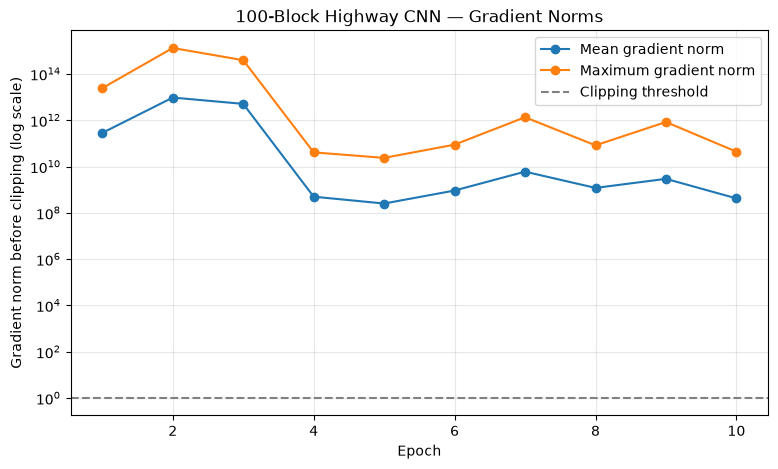

In [20]:
import matplotlib.pyplot as plt

epochs = range(1, len(stable_history["mean_grad_norm"]) + 1)

plt.figure(figsize=(9, 5))

plt.plot(
    epochs,
    stable_history["mean_grad_norm"],
    marker="o",
    label="Mean gradient norm",
)

plt.plot(
    epochs,
    stable_history["max_grad_norm"],
    marker="o",
    label="Maximum gradient norm",
)

plt.axhline(
    1.0,
    linestyle="--",
    color="gray",
    label="Clipping threshold",
)

plt.yscale("log")
plt.xlabel("Epoch")
plt.ylabel("Gradient norm before clipping (log scale)")
plt.title("100-Block Highway CNN — Gradient Norms")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

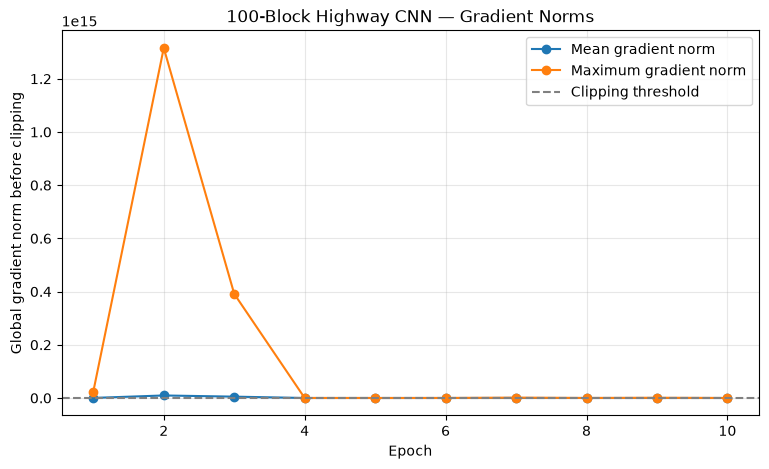

In [21]:
plt.figure(figsize=(9, 5))

plt.plot(
    epochs,
    stable_history["mean_grad_norm"],
    marker="o",
    label="Mean gradient norm",
)

plt.plot(
    epochs,
    stable_history["max_grad_norm"],
    marker="o",
    label="Maximum gradient norm",
)

plt.axhline(
    MAX_GRAD_NORM,
    linestyle="--",
    color="gray",
    label="Clipping threshold",
)

plt.xlabel("Epoch")
plt.ylabel("Global gradient norm before clipping")
plt.title("100-Block Highway CNN — Gradient Norms")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


### 9.10 Training Stability Experiment Results

We retrained the 100-block Highway CNN with a smaller learning rate and global gradient clipping.

#### Experimental Results

| Metric | Original Run | Stability Run |
|---|---:|---:|
| Learning rate | 0.001 | 0.0001 |
| Gradient clipping | None | Max norm 1.0 |
| Internal blocks | 100 | 100 |
| Training epochs | 10 | 10 |
| Best validation accuracy | 36.48% | 12.02% |
| Best epoch | 8 | 6 |
| Final validation accuracy | 9.86% | 11.06% |
| Final validation loss | 2.3032 | 64.5020 |
| Training time | 226.0 min | 218.5 min |

#### Gradient Analysis

The experiment recorded extremely large gradient norms before clipping.

At epoch 2, the maximum observed global gradient norm was approximately:

$$
\boxed{\|g\|_2 \approx 1.32 \times 10^{15}}
$$

This suggests severe numerical amplification during training.

Gradient clipping limits the norm of gradients before the optimizer update, but does not guarantee stable intermediate activations or parameter updates.

#### Observations

1. The original run learned until epoch 8, then collapsed.
2. The stability run did not achieve sustained learning.
3. Decreasing the learning rate from 0.001 to 0.0001 did not resolve the instability.
4. Gradient norms were extremely large despite clipping being enabled.
5. The stability experiment achieved only 12.02% best validation accuracy, compared with 36.48% in the original run.

#### Conclusion

The experiment demonstrates that the 100-block Highway CNN remains difficult to optimize with our current initialization and training configuration.

A smaller learning rate and gradient clipping alone were insufficient.

Further investigation should focus on:

- Initial transform gate behavior.
- Hidden activation magnitudes.
- Gradient propagation through the network.
- Initialization strategies for very deep Highway Networks.

**Key takeaway:** Highway connections can improve trainability, but they do not automatically guarantee stable optimization at arbitrary network depth.


In [22]:
import torch

for bias in [-2.0, -3.0, -4.0, -5.0]:
    transform = torch.sigmoid(torch.tensor(bias)).item()
    carry = 1 - transform

    print(
        f"Gate bias: {bias:+.1f} | "
        f"Transform: {transform:.4f} | "
        f"Carry: {carry:.4f}"
    )

Gate bias: -2.0 | Transform: 0.1192 | Carry: 0.8808
Gate bias: -3.0 | Transform: 0.0474 | Carry: 0.9526
Gate bias: -4.0 | Transform: 0.0180 | Carry: 0.9820
Gate bias: -5.0 | Transform: 0.0067 | Carry: 0.9933


In [23]:
torch.manual_seed(SEED)

diagnostic_model = build_model("highway", 100).to(device)
diagnostic_model.eval()

sample_images, _ = next(iter(val_loader))
sample_images = sample_images[:4].to(device)

with torch.no_grad():
    x = diagnostic_model.features(sample_images)

    print(f"After initial conv: RMS = {x.square().mean().sqrt().item():.4f}")

    for i, layer in enumerate(diagnostic_model.highway_layers, start=1):
        x = layer(x)

        if i in (1, 10, 25, 50, 75, 100):
            rms = x.square().mean().sqrt().item()
            max_abs = x.abs().max().item()

            print(
                f"Block {i:3d} | "
                f"RMS: {rms:.4f} | "
                f"Max absolute activation: {max_abs:.4f}"
            )

            assert torch.isfinite(x).all(), "Non-finite activation!"

del diagnostic_model

After initial conv: RMS = 0.4167
Block   1 | RMS: 0.3710 | Max absolute activation: 2.4578
Block  10 | RMS: 0.1514 | Max absolute activation: 0.9140
Block  25 | RMS: 0.0371 | Max absolute activation: 0.1605
Block  50 | RMS: 0.0168 | Max absolute activation: 0.0278
Block  75 | RMS: 0.0152 | Max absolute activation: 0.0299
Block 100 | RMS: 0.0155 | Max absolute activation: 0.0291


In [29]:
import torch

GATE_BIASES = [-2.0, -3.0, -4.0, -5.0]
CHECKPOINT_LAYERS = [1, 10, 25, 50, 75, 100]

sample_images, _ = next(iter(val_loader))
sample_images = sample_images[:4].to(device)

bias_results = {}

for bias in GATE_BIASES:
    torch.manual_seed(SEED)

    net = build_model("highway", 100).to(device)
    net.eval()

    with torch.no_grad():
        # Change only the gate biases
        for layer in net.highway_layers:
            torch.nn.init.constant_(layer.gate.bias, bias)

        x = net.features(sample_images)

        rms_values = {
            0: x.square().mean().sqrt().item()
        }

        for i, layer in enumerate(net.highway_layers, start=1):
            x = layer(x)

            if i in CHECKPOINT_LAYERS:
                rms_values[i] = x.square().mean().sqrt().item()

    bias_results[bias] = rms_values

    print(f"\nGate bias: {bias}")
    for layer_number, rms in rms_values.items():
        print(f"  Block {layer_number:3d}: RMS = {rms:.6f}")

    del net

print("\nExperiment completed!")


Gate bias: -2.0
  Block   0: RMS = 0.416687
  Block   1: RMS = 0.371035
  Block  10: RMS = 0.151366
  Block  25: RMS = 0.037116
  Block  50: RMS = 0.016844
  Block  75: RMS = 0.015236
  Block 100: RMS = 0.015535

Gate bias: -3.0
  Block   0: RMS = 0.416687
  Block   1: RMS = 0.398119
  Block  10: RMS = 0.276189
  Block  25: RMS = 0.149606
  Block  50: RMS = 0.059613
  Block  75: RMS = 0.027940
  Block 100: RMS = 0.018929

Gate bias: -4.0
  Block   0: RMS = 0.416687
  Block   1: RMS = 0.409581
  Block  10: RMS = 0.355592
  Block  25: RMS = 0.280151
  Block  50: RMS = 0.192039
  Block  75: RMS = 0.132730
  Block 100: RMS = 0.092563

Gate bias: -5.0
  Block   0: RMS = 0.416687
  Block   1: RMS = 0.414033
  Block  10: RMS = 0.392615
  Block  25: RMS = 0.358771
  Block  50: RMS = 0.310514
  Block  75: RMS = 0.269540
  Block 100: RMS = 0.233284

Experiment completed!


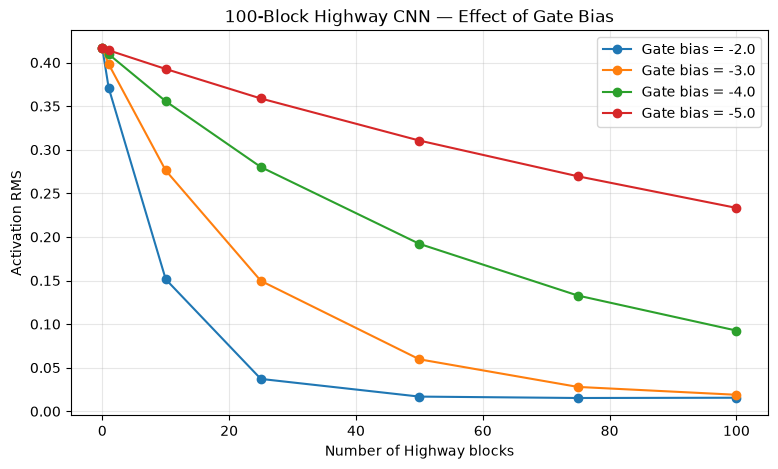

In [30]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

for bias, values in bias_results.items():
    plt.plot(
        list(values.keys()),
        list(values.values()),
        marker="o",
        label=f"Gate bias = {bias}",
    )

plt.xlabel("Number of Highway blocks")
plt.ylabel("Activation RMS")
plt.title("100-Block Highway CNN — Effect of Gate Bias")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


### 9.11 Gate Bias Experiment — Results

We investigated how the initial transform gate bias affects activation magnitudes in a 100-block Highway CNN.

We compared four bias values:

$$
b_T \in \{-2,-3,-4,-5\}
$$

All experiments used identical initial convolution weights, transformation weights, gate weights, and input images. Only the transform gate biases were changed.

### Experimental Results

| Gate Bias | Initial RMS | RMS at Block 100 | RMS Ratio |
|---|---:|---:|---:|
| -2.0 | 0.416687 | 0.015535 | 3.7% |
| -3.0 | 0.416687 | 0.018929 | 4.5% |
| -4.0 | 0.416687 | 0.092563 | 22.2% |
| -5.0 | 0.416687 | 0.233284 | 56.0% |

The RMS ratio is calculated as:

$$
R = \frac{\operatorname{RMS}(x_{100})}
{\operatorname{RMS}(x_0)} \times 100\%
$$

### Observations

1. **Negative gate bias affects information flow.**

   More negative biases produce smaller initial transform gate values and larger carry gate values.

2. **Gate bias -2.0 caused substantial activation attenuation.**

   The activation RMS decreased from 0.416687 to 0.015535.

3. **Gate bias -5.0 preserved activation magnitude more effectively.**

   The activation RMS remained at 0.233284 after 100 blocks.

4. **The influence accumulates with depth.**

   Small differences in gate behavior become more significant when repeated across many layers.

5. **Activation preservation does not guarantee training stability.**

   The experiment measures initialization behavior, not final classification performance or gradient stability during training.

### Conclusion

Using a more negative transform gate bias makes the initial 100-block Highway Network behave closer to an identity-preserving architecture.

Among the tested values, **-5.0 produced the highest activation RMS at block 100**.

This provides a reason to investigate whether more negative bias initialization improves optimization in very deep Highway Networks.


In [31]:
def inspect_input_gradient(gate_bias):
    torch.manual_seed(SEED)

    net = build_model("highway", 100).to(device)

    with torch.no_grad():
        for layer in net.highway_layers:
            layer.gate.bias.fill_(gate_bias)

    net.train()
    net.zero_grad(set_to_none=True)

    images, labels = next(iter(val_loader))
    images = images[:4].to(device)
    labels = labels[:4].to(device)

    logits = net(images)
    loss = nn.CrossEntropyLoss()(logits, labels)

    loss.backward()

    # Examine gradient norm in the initial convolution
    initial_grad = net.features[0].weight.grad.norm().item()

    # Examine gradients in early and late Highway blocks
    early_grad = net.highway_layers[0].transform.weight.grad.norm().item()
    late_grad = net.highway_layers[-1].transform.weight.grad.norm().item()

    print(f"\nGate bias: {gate_bias}")
    print(f"Loss: {loss.item():.4f}")
    print(f"Initial convolution grad norm: {initial_grad:.6e}")
    print(f"First Highway block grad norm: {early_grad:.6e}")
    print(f"Last Highway block grad norm: {late_grad:.6e}")

    del net, logits, loss


inspect_input_gradient(-2.0)
inspect_input_gradient(-5.0)


Gate bias: -2.0
Loss: 2.3014
Initial convolution grad norm: 2.895958e-06
First Highway block grad norm: 5.510399e-07
Last Highway block grad norm: 6.173586e-03

Gate bias: -5.0
Loss: 2.1898
Initial convolution grad norm: 3.540761e-01
First Highway block grad norm: 4.164357e-03
Last Highway block grad norm: 3.702605e-03



### 9.12 Gradient Propagation Experiment

We investigated how transform gate bias initialization affects gradient propagation through a 100-block Highway CNN.

We compared two configurations:

$$
b_T=-2.0
$$

$$
b_T=-5.0
$$

Both models used identical random initialization and the same input batch. Only the transform gate biases differed.

### Experimental Results

| Gradient Location | Bias -2.0 | Bias -5.0 |
|---|---:|---:|
| Initial convolution | $2.896\times10^{-6}$ | $3.541\times10^{-1}$ |
| First Highway block | $5.510\times10^{-7}$ | $4.164\times10^{-3}$ |
| Last Highway block | $6.174\times10^{-3}$ | $3.703\times10^{-3}$ |

### Observations

1. **Bias -2.0 produces extremely small gradients in early layers.**

   The initial convolution and first Highway block receive much smaller gradients than the final Highway block.

2. **Bias -5.0 improves gradient propagation at initialization.**

   The initial convolution gradient increases substantially, while the first Highway block also receives a larger gradient.

3. **The effect is consistent with activation preservation.**

   Our previous experiment showed that bias -5.0 also preserves larger activation magnitudes through 100 blocks.

4. **More negative biases favor the carry path.**

   The Highway equation is:

   $$
   y=H(x)T(x)+x(1-T(x))
   $$

   When the transform gate is small, the layer behaves approximately like an identity mapping.

5. **Larger gradients do not automatically guarantee better training.**

   These measurements were taken at initialization using a small batch. They do not establish whether gradient explosion or collapse will occur later.

### Conclusion

Our experiments indicate that transform gate initialization strongly influences activation and gradient propagation in very deep Highway Networks.

Among the tested configurations, bias **-5.0** provided substantially better initial activation preservation and stronger gradient propagation to early layers than bias -2.0.

This makes bias -5.0 a promising candidate for another controlled training experiment.

However, training stability and classification performance must still be evaluated empirically.



### 9.13 Testing Gate Bias -5.0 During Training

#### Objective

Our previous experiments showed that changing the transform gate bias from $-2.0$ to $-5.0$ improved activation preservation and gradient propagation at initialization.

We now investigate whether this improved initialization leads to better training behavior.

#### Experimental Configuration

| Hyperparameter | Original 100-Block Run | New Experiment |
|---|---|---|
| Internal blocks | 100 | 100 |
| Gate bias | -2.0 | -5.0 |
| Learning rate | 0.001 | 0.001 |
| Optimizer | Adam | Adam |
| Gradient clipping | None | None |
| Feature channels | 32 | 32 |
| Batch size | 128 | 128 |
| Random seed | 42 | 42 |
| Initial training | 10 epochs | 1 epoch |

#### Hypothesis

A more negative gate bias initially favors the carry path:

$$
T(x)=\sigma(W_Tx+b_T)
$$

For $b_T=-5$ and $W_Tx=0$:

$$
T(x)=\sigma(-5)\approx0.0067
$$

$$
1-T(x)\approx0.9933
$$

This makes the layer closer to an identity mapping at initialization.

We hypothesize that this may help preserve information and gradients through 100 Highway blocks.

#### Evaluation

After one epoch, we will examine:

1. Training and validation loss.
2. Training and validation accuracy.
3. Mean and maximum gradient norms before any clipping.
4. Whether the optimizer encounters non-finite values.

**Important:** One successful epoch does not guarantee stability over longer training.


In [32]:
import time
import torch
import torch.nn as nn

EXPERIMENT_DEPTH = 100
EXPERIMENT_GATE_BIAS = -5.0
EXPERIMENT_LR = 0.001

checkpoint_dir = PROJECT_ROOT / "checkpoints" / "depth_experiments"
checkpoint_dir.mkdir(parents=True, exist_ok=True)

# Reproducible initialization
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

bias5_model = build_model("highway", EXPERIMENT_DEPTH).to(device)

# Change only the transform gate biases
with torch.no_grad():
    for layer in bias5_model.highway_layers:
        layer.gate.bias.fill_(EXPERIMENT_GATE_BIAS)

bias5_optimizer = torch.optim.Adam(
    bias5_model.parameters(),
    lr=EXPERIMENT_LR,
)

bias5_criterion = nn.CrossEntropyLoss()
bias5_loader = make_train_loader(seed=SEED)

bias5_history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": [],
    "mean_grad_norm": [],
    "max_grad_norm": [],
}

print("Training Highway CNN — 100 blocks")
print("Gate bias:", EXPERIMENT_GATE_BIAS)
print("Learning rate:", EXPERIMENT_LR)
print("Gradient clipping: Disabled")

started = time.perf_counter()

bias5_model.train()

total_loss = 0.0
correct = 0
total = 0

gradient_norms = []

for images, labels in bias5_loader:
    images = images.to(device, non_blocking=True)
    labels = labels.to(device, non_blocking=True)

    bias5_optimizer.zero_grad(set_to_none=True)

    logits = bias5_model(images)
    loss = bias5_criterion(logits, labels)

    if not torch.isfinite(loss).item():
        raise RuntimeError("Non-finite training loss detected!")

    loss.backward()

    # Measure gradient norm without modifying gradients
    grad_norm = torch.nn.utils.clip_grad_norm_(
        bias5_model.parameters(),
        max_norm=float("inf"),
        error_if_nonfinite=True,
    )

    gradient_norms.append(grad_norm.item())

    bias5_optimizer.step()

    batch_size = labels.size(0)

    total_loss += loss.item() * batch_size
    correct += (logits.argmax(dim=1) == labels).sum().item()
    total += batch_size

train_loss = total_loss / total
train_acc = 100 * correct / total

val_loss, val_acc = evaluate(
    bias5_model,
    val_loader,
    bias5_criterion,
)

mean_grad = sum(gradient_norms) / len(gradient_norms)
max_grad = max(gradient_norms)

bias5_history["train_loss"].append(train_loss)
bias5_history["train_accuracy"].append(train_acc)
bias5_history["val_loss"].append(val_loss)
bias5_history["val_accuracy"].append(val_acc)
bias5_history["mean_grad_norm"].append(mean_grad)
bias5_history["max_grad_norm"].append(max_grad)

elapsed = time.perf_counter() - started

print("\nEpoch 01/01")
print(f"Train loss: {train_loss:.4f}")
print(f"Train accuracy: {train_acc:.2f}%")
print(f"Validation loss: {val_loss:.4f}")
print(f"Validation accuracy: {val_acc:.2f}%")
print(f"Mean gradient norm: {mean_grad:.4e}")
print(f"Maximum gradient norm: {max_grad:.4e}")
print(f"Training time: {elapsed / 60:.1f} minutes")

# Preserve the complete state for continuing training
bias5_checkpoint = checkpoint_dir / "highway_100blocks_bias5_latest.pth"

torch.save(
    {
        "epoch": 1,
        "model_state_dict": bias5_model.state_dict(),
        "optimizer_state_dict": bias5_optimizer.state_dict(),
        "history": bias5_history,
        "depth": EXPERIMENT_DEPTH,
        "channels": CHANNELS,
        "gate_bias": EXPERIMENT_GATE_BIAS,
        "learning_rate": EXPERIMENT_LR,
        "seed": SEED,
    },
    bias5_checkpoint,
)

print("\nCheckpoint saved:", bias5_checkpoint)

Training Highway CNN — 100 blocks
Gate bias: -5.0
Learning rate: 0.001
Gradient clipping: Disabled

Epoch 01/01
Train loss: 2.3509
Train accuracy: 22.39%
Validation loss: 1.9344
Validation accuracy: 28.00%
Mean gradient norm: 5.5252e+02
Maximum gradient norm: 1.2162e+05
Training time: 35.9 minutes

Checkpoint saved: C:\Users\rbern\Desktop\DL\highway-networks\checkpoints\depth_experiments\highway_100blocks_bias5_latest.pth


In [33]:
original = deep_results[("highway", 100)]["history"]

print("100-Block Highway CNN — Epoch 1 Comparison")
print("-" * 55)

print(
    f"{'Metric':<25}"
    f"{'Bias -2':>14}"
    f"{'Bias -5':>14}"
)

metrics = [
    ("Train loss", "train_loss"),
    ("Train accuracy (%)", "train_accuracy"),
    ("Validation loss", "val_loss"),
    ("Validation accuracy (%)", "val_accuracy"),
]

for label, key in metrics:
    print(
        f"{label:<25}"
        f"{original[key][0]:>14.4f}"
        f"{bias5_history[key][0]:>14.4f}"
    )

100-Block Highway CNN — Epoch 1 Comparison
-------------------------------------------------------
Metric                          Bias -2       Bias -5
Train loss                       2.3039        2.3509
Train accuracy (%)              10.0178       22.3889
Validation loss                  2.3031        1.9344
Validation accuracy (%)          9.8600       28.0000



### 9.14 Gate Bias -5.0 — First Epoch Results

We trained a 100-block Highway CNN using transform gate bias $-5.0$ and compared its first epoch against the original configuration with bias $-2.0$.

### Experimental Results

| Metric | Bias -2.0 | Bias -5.0 |
|---|---:|---:|
| Training loss | 2.3039 | 2.3509 |
| Training accuracy | 10.02% | **22.39%** |
| Validation loss | 2.3031 | **1.9344** |
| Validation accuracy | 9.86% | **28.00%** |

The validation accuracy improvement was:

$$
\Delta A = 28.00\%-9.86\%
$$

$$
\boxed{\Delta A=18.14\text{ percentage points}}
$$

### Gradient Diagnostics

| Metric | Value |
|---|---:|
| Mean global gradient norm | 552.52 |
| Maximum global gradient norm | 121,620 |
| Gradient clipping | Disabled |

The gradients were finite, but some batches produced very large global gradient norms.

These observations suggest possible optimization instability. The gradient norms alone do not establish whether training will collapse in later epochs.

### Observations

1. A more negative transform gate bias significantly improved first-epoch validation accuracy.
2. The model learned useful classification patterns during the first epoch.
3. Validation loss decreased substantially compared with the original experiment.
4. The average training loss was higher, potentially reflecting large losses on individual batches.
5. Large gradient norms indicate that training stability still requires monitoring.

### Conclusion

Initializing the transform gate bias to $-5.0$ substantially improved early optimization in our 100-block Highway CNN.

This is consistent with our earlier activation and gradient propagation experiments.

However, one epoch is insufficient to establish long-term training stability or final classification performance.


In [34]:
import torch
import torch.nn as nn
import time

checkpoint_dir = PROJECT_ROOT / "checkpoints" / "depth_experiments"

latest_path = checkpoint_dir / "highway_100blocks_bias5_latest.pth"
best_path = checkpoint_dir / "highway_100blocks_bias5_best.pth"

checkpoint = torch.load(
    latest_path,
    map_location=device,
    weights_only=True,
)

# Reconstruct the exact model architecture
model = build_model("highway", checkpoint["depth"]).to(device)

# Restore learned weights, including gate biases
model.load_state_dict(checkpoint["model_state_dict"])

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=checkpoint["learning_rate"],
)
optimizer.load_state_dict(checkpoint["optimizer_state_dict"])

criterion = nn.CrossEntropyLoss()

history = checkpoint["history"]
start_epoch = checkpoint["epoch"] + 1
end_epoch = 10

loader = make_train_loader(seed=SEED)

# Epoch 1 is currently the best completed epoch
best_val_accuracy = max(history["val_accuracy"])
best_epoch = history["val_accuracy"].index(best_val_accuracy) + 1

# Preserve the original epoch-1 model as the initial best
if not best_path.exists():
    torch.save(checkpoint, best_path)

print(f"Resuming from epoch {start_epoch}")
print(f"Current best validation accuracy: {best_val_accuracy:.2f}%")

started = time.perf_counter()

for epoch in range(start_epoch, end_epoch + 1):

    # Reuse our gradient-monitoring training function
    train_loss, train_acc, mean_grad, max_grad = (
        train_one_epoch_stable(
            model,
            loader,
            criterion,
            optimizer,
            max_grad_norm=float("inf"),  # Monitor only; no clipping
        )
    )

    val_loss, val_acc = evaluate(
        model,
        val_loader,
        criterion,
    )

    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_acc)
    history["mean_grad_norm"].append(mean_grad)
    history["max_grad_norm"].append(max_grad)

    print(
        f"Epoch {epoch:02d}/{end_epoch} | "
        f"Train loss: {train_loss:.4f} | "
        f"Train acc: {train_acc:.2f}% | "
        f"Val loss: {val_loss:.4f} | "
        f"Val acc: {val_acc:.2f}% | "
        f"Mean grad: {mean_grad:.2e} | "
        f"Max grad: {max_grad:.2e}",
        flush=True,
    )

    checkpoint_data = {
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "history": history,
        "depth": checkpoint["depth"],
        "channels": checkpoint["channels"],
        "gate_bias": checkpoint["gate_bias"],
        "learning_rate": checkpoint["learning_rate"],
        "seed": checkpoint["seed"],
    }

    if val_acc > best_val_accuracy:
        best_val_accuracy = val_acc
        best_epoch = epoch
        torch.save(checkpoint_data, best_path)

    torch.save(checkpoint_data, latest_path)

elapsed = time.perf_counter() - started

print("\nTraining complete!")
print(f"Additional training time: {elapsed / 60:.1f} minutes")
print(f"Best epoch: {best_epoch}")
print(f"Best validation accuracy: {best_val_accuracy:.2f}%")
print(f"Final validation accuracy: {history['val_accuracy'][-1]:.2f}%")

Resuming from epoch 2
Current best validation accuracy: 28.00%
Epoch 02/10 | Train loss: 1.8012 | Train acc: 31.80% | Val loss: 1.7677 | Val acc: 32.42% | Mean grad: 2.96e+00 | Max grad: 7.20e+00
Epoch 03/10 | Train loss: 120.1814 | Train acc: 29.77% | Val loss: 2.1713 | Val acc: 16.70% | Mean grad: 1.49e+05 | Max grad: 4.02e+07


KeyboardInterrupt: 

In [35]:
import torch

best_path = (
    PROJECT_ROOT
    / "checkpoints"
    / "depth_experiments"
    / "highway_100blocks_bias5_best.pth"
)

best_checkpoint = torch.load(
    best_path,
    map_location="cpu",
    weights_only=True,
)

print("Best saved epoch:", best_checkpoint["epoch"])
print(
    "Validation accuracy:",
    best_checkpoint["history"]["val_accuracy"][-1],
)

Best saved epoch: 2
Validation accuracy: 32.42



### 9.15 Gate Bias -5.0 — Continued Training Results

We continued training the 100-block Highway CNN initialized with transform gate bias $-5.0$.

The optimizer was Adam with learning rate $0.001$, without gradient clipping.

#### Results

| Metric | Epoch 1 | Epoch 2 | Epoch 3 |
|---|---:|---:|---:|
| Training loss | 2.3509 | 1.8012 | 120.1814 |
| Training accuracy | 22.39% | 31.80% | 29.77% |
| Validation loss | 1.9344 | 1.7677 | 2.1713 |
| Validation accuracy | 28.00% | **32.42%** | 16.70% |
| Mean gradient norm | 552.52 | 2.96 | 149,000 |
| Maximum gradient norm | 121,620 | 7.20 | 40,200,000 |

#### Observations

1. The network learned successfully during the first two epochs.
2. Validation accuracy improved to 32.42% at epoch 2.
3. During epoch 3, training loss increased dramatically.
4. The maximum global gradient norm reached approximately $4.02 \times 10^7$.
5. Validation accuracy dropped to 16.70%, indicating a severe deterioration in model performance.

#### Conclusion

Using gate bias $-5.0$ improved initial gradient propagation and early training performance compared with the original bias $-2.0$.

However, this initialization did not eliminate training instability.

The results suggest that both gate initialization and optimization settings influence the training behavior of very deep Highway Networks.

**Best observed checkpoint in this run:** Epoch 2, with 32.42% validation accuracy.

These findings support the need for further investigation into gradient stability and parameter updates in very deep architectures.
